# Классификация серьёзных повреждений автомобиля

## 1. Загрузка фото

In [68]:
from pathlib import Path

from PIL import Image, ImageOps

image_path = Path("../outputs/1.png")

with Image.open(image_path) as source:
    image = ImageOps.exif_transpose(source).convert("RGB")

## 2. Загрузка CLIP

In [69]:
import huggingface_hub

if not hasattr(huggingface_hub, "is_offline_mode"):
    raise RuntimeError(
        f"Ядро загрузило huggingface-hub {huggingface_hub.__version__}. "
        "Установите huggingface-hub==1.3.0 для этого ядра, если пакет ещё не обновлён, "
        "затем нажмите Restart Kernel и запустите ячейки с начала."
    )

import torch
from transformers import CLIPModel, CLIPProcessor

model_id = "openai/clip-vit-base-patch32"
cache_dir = Path("../models/clip")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

processor = CLIPProcessor.from_pretrained(model_id, cache_dir=cache_dir)
model = CLIPModel.from_pretrained(
    model_id, cache_dir=cache_dir, use_safetensors=False,
).to(device).eval()

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 727.95it/s, Materializing param=visual_projection.weight]                                
CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## 3. Описания классов

Серьёзными считаются видимые повреждения, которые могут лишить автомобиль возможности двигаться, например смятая несущая часть кузова или разрушенное крепление колеса. Второй класс включает целый кузов и косметические дефекты.

In [70]:
class_prompts = {
    "Есть серьёзные повреждения": [
        "a photo of a car wreck with major structural damage",
        "a photo of a crashed car with a severely crushed front or rear end",
        "a photo of a wrecked car with a collapsed roof or cabin",
        "a photo of a severely damaged car with a broken wheel or axle",
    ],
    "Нет видимых серьёзных повреждений": [
        "a photo of an intact car in good condition",
        "a photo of a car with minor scratches on the bodywork",
        "a photo of a car with a small cosmetic dent and an intact body",
        "a photo of a car with a scuffed bumper and intact wheels",
    ],
}

## 4. Сравнение фото с описаниями

Дополняем фото до квадрата, чтобы в кадр попало всё авто. Для каждого класса усредняем оценки его описаний, затем применяем `softmax` к двум средним оценкам.

In [71]:
image_size = model.config.vision_config.image_size
model_image = ImageOps.pad(
    image, (image_size, image_size), method=Image.Resampling.BICUBIC, color=(127, 127, 127),
)

prompts = [prompt for group in class_prompts.values() for prompt in group]
inputs = processor(text=prompts, images=model_image, padding=True, return_tensors="pt").to(device)

with torch.inference_mode():
    prompt_logits = model(**inputs).logits_per_image[0]

prompt_counts = [len(group) for group in class_prompts.values()]
class_logits = torch.stack([group.mean() for group in prompt_logits.split(prompt_counts)])
class_scores = dict(zip(class_prompts, class_logits.softmax(dim=0).tolist()))
predicted_class = max(class_scores, key=class_scores.get)

## 5. Результат CLIP

Проценты показывают относительные оценки двух классов для выбранных описаний. Близкие оценки означают, что CLIP слабо различает классы на этом фото.

In [72]:
print(f"Результат: {predicted_class}")
for label, score in class_scores.items():
    print(f"{label}: {score:.2%}")

Результат: Есть серьёзные повреждения
Есть серьёзные повреждения: 57.69%
Нет видимых серьёзных повреждений: 42.31%


## 6. Проверка через SigLIP 2

Используем то же фото и те же описания классов. При первом запуске модель скачает около 1,5 ГБ в `../models/siglip2`.

In [73]:
from transformers import AutoImageProcessor, AutoModel, GemmaTokenizer, SiglipProcessor

siglip_model_id = "google/siglip2-base-patch16-224"
siglip_cache_dir = Path("../models/siglip2")
siglip_image_processor = AutoImageProcessor.from_pretrained(siglip_model_id, cache_dir=siglip_cache_dir)
siglip_tokenizer = GemmaTokenizer.from_pretrained(siglip_model_id, cache_dir=siglip_cache_dir)
siglip_processor = SiglipProcessor(siglip_image_processor, siglip_tokenizer)
siglip_model = AutoModel.from_pretrained(siglip_model_id, cache_dir=siglip_cache_dir).to(device).eval()

Loading weights: 100%|██████████| 408/408 [00:00<00:00, 660.46it/s, Materializing param=vision_model.post_layernorm.weight]                      


## 7. Результат SigLIP 2

SigLIP 2 оценивает каждое описание через `sigmoid`. Для класса берём среднее его оценок и выбираем класс с большим средним. Для наглядности применяем `softmax` к двум средним оценкам. Полученные проценты в сумме дают 100% и показывают относительное предпочтение между классами.

In [74]:
siglip_inputs = siglip_processor(
    text=prompts, images=model_image, padding="max_length", max_length=64, return_tensors="pt",
).to(device)

with torch.inference_mode():
    siglip_prompt_scores = siglip_model(**siglip_inputs).logits_per_image[0].sigmoid()

siglip_scores = {
    label: group.mean().item()
    for label, group in zip(class_prompts, siglip_prompt_scores.split(prompt_counts))
}
siglip_class = max(siglip_scores, key=siglip_scores.get)
siglip_display_scores = torch.tensor(list(siglip_scores.values()), dtype=torch.float64)

print(f"Результат: {siglip_class}")
for label, score in zip(siglip_scores, siglip_display_scores.tolist()):
    print(f"{label}: {score:.2}")

Результат: Нет видимых серьёзных повреждений
Есть серьёзные повреждения: 0.0036
Нет видимых серьёзных повреждений: 0.013


## 8. Фото автомобиля

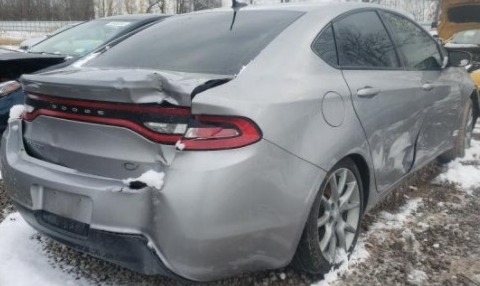

In [75]:
from IPython.display import display

display(image)